# DATA SCIENCE CAPSTONE PROJECT
## Pengelolaan dan Pemantauan Stok Harian UMKM ROKKUS Mardani Raya

Notebook ini memuat dua kelompok analisis yang **dibedakan secara tegas**:

1. **Dataset publik referensi inventaris** (`warehouses`, `stock_items`, `stock_movements`) untuk mempelajari struktur data, transaksi masuk/keluar, tanggal pencatatan, dan konsep reorder point.
2. **Dataset simulasi ROKKUS** (`dataset_bahan_baku_final.csv` dan `dataset_produk_jadi_final.csv`) untuk EDA, visualisasi, dan pengujian dataset yang disiapkan untuk proyek UMKM.

> **Batasan interpretasi:** dataset publik berisi contoh barang non-kuliner seperti Bluetooth Speaker, Yoga Mat, dan Desk Lamp. Dataset tersebut bukan catatan ROKKUS dan tidak boleh dianggap mewakili menu, bahan, jumlah stok, atau transaksi aktual ROKKUS. Dataset simulasi ROKKUS juga bukan catatan operasional aktual, kecuali ada data yang secara khusus telah dikonfirmasi oleh UMKM.

## 1. Business Understanding

ROKKUS Mardani Raya merupakan UMKM kuliner yang menjual produk roti kukus dan roti bakar. Berdasarkan konteks proyek, pencatatan dan pembaruan data operasional masih dilakukan secara manual menggunakan Microsoft Excel dan catatan lainnya. Kondisi tersebut menjadi dasar pengembangan aplikasi pengelolaan dan pemantauan stok harian.

### Tujuan analisis
1. Memahami struktur dan kualitas data inventaris.
2. Membedakan transaksi barang masuk dan barang keluar.
3. Menghitung estimasi stok akhir serta mengidentifikasi item di bawah reorder point.
4. Melakukan EDA dan visualisasi dataset simulasi bahan baku dan produk jadi ROKKUS.
5. Melakukan pengujian dasar terhadap konsistensi dataset final.

### Mengapa dataset publik digunakan?
Dataset publik digunakan sebagai **referensi metode dan struktur analisis**, bukan sebagai data ROKKUS. Beberapa konsepnya dapat dijelaskan dalam konteks ROKKUS sebagai berikut:

| Kolom dataset referensi | Makna pada dataset referensi | Konsep yang dapat diadaptasi ke ROKKUS |
|---|---|---|
| `reorder_point` | Batas stok untuk memicu pengadaan ulang | Batas minimum bahan baku/produk yang perlu dipantau |
| `lead_time_days` | Perkiraan waktu tunggu sejak pemesanan sampai barang diterima | Waktu tunggu pemasok bahan seperti roti kukus siap pakai, selai, telur, sosis, atau kemasan |
| `movement_type` | Jenis pergerakan persediaan, misalnya `sale` dan `receipt` | Jenis aktivitas stok masuk/keluar; perlu disesuaikan dengan alur operasional ROKKUS |

**Catatan penting:** nilai `reorder_point` dan `lead_time_days` pada dataset publik tidak dipindahkan sebagai nilai aktual ROKKUS. Penetapan batas minimum dan lead time ROKKUS perlu berdasarkan konfirmasi UMKM dan riwayat pembelian. Karena data masa simpan/kedaluwarsa bahan belum tersedia dalam dataset ini, notebook tidak membuat klaim atau perhitungan shelf life.

## 2. Import Library

In [7]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Library berhasil diimpor.")

Library berhasil diimpor.


## 3. Memuat Dataset Publik Referensi

Dataset diambil dari sumber Database Sample. Jika lingkungan tidak memiliki akses internet, unggah tiga file CSV referensi secara manual dan sesuaikan bagian pemuatan data.

In [8]:
base_url = "https://database-sample-website.s3.eu-north-1.amazonaws.com/datasets/inventory-stock-movements-and-reorder-point-thresholds/v1/csv/"

try:
    warehouses = pd.read_csv(base_url + "warehouses.csv")
    stock_items = pd.read_csv(base_url + "stock_items.csv")
    stock_movements = pd.read_csv(base_url + "stock_movements.csv")
    print("Dataset publik berhasil dimuat dari sumber online.")
except Exception as e:
    print("Gagal memuat dataset dari sumber online.")
    print("Jika diperlukan, unggah warehouses.csv, stock_items.csv, dan stock_movements.csv.")
    raise e

print("Warehouses:", warehouses.shape)
print("Stock items:", stock_items.shape)
print("Stock movements:", stock_movements.shape)

Dataset publik berhasil dimuat dari sumber online.
Warehouses: (4, 5)
Stock items: (80, 9)
Stock movements: (543, 7)


## 4. Data Understanding dan Data Quality Assessment

Pemeriksaan berikut dibuat satu kali untuk menghindari pengulangan pemeriksaan bentuk data, sampel, missing values, dan duplikasi.

In [9]:
datasets_referensi = {
    "warehouses": warehouses,
    "stock_items": stock_items,
    "stock_movements": stock_movements
}

for nama, df in datasets_referensi.items():
    print(f"\n===== {nama.upper()} =====")
    print("Ukuran:", df.shape)
    print("\nTipe data:")
    display(df.dtypes.rename("dtype").to_frame())
    print("\nSampel:")
    display(df.head())
    print("\nMissing values:")
    display(df.isna().sum().rename("jumlah_missing").to_frame())
    print("\nJumlah baris duplikat:", df.duplicated().sum())


===== WAREHOUSES =====
Ukuran: (4, 5)

Tipe data:


,dtype
id,int64
code,object
city,object
dock_doors,int64
opened_on,object



Sampel:


,id,code,city,dock_doors,opened_on
0,1,WH-14,Fort Meggiechester,20,2020-04-27
1,2,WH-79,South Bernieceview,7,2015-06-17
2,3,WH-34,Port Lisatown,8,2015-03-01
3,4,WH-54,National City,11,2022-03-07



Missing values:


,jumlah_missing
id,0
code,0
city,0
dock_doors,0
opened_on,0


... (9 outputs left out)

,id,stock_item_id,movement_type,units_in,units_out,quantity_change,moved_at
0,1,59,adjustment,NaN,2.0,-2,2024-09-01 08:57:34
1,2,23,adjustment,NaN,1.0,-1,2024-09-01 10:48:54
2,3,15,transfer_out,NaN,7.0,-7,2024-09-01 04:59:26
3,4,10,sale,NaN,1.0,-1,2024-09-01 16:04:59
4,5,71,sale,NaN,11.0,-11,2024-09-01 04:50:23



Missing values:


,jumlah_missing
id,0
stock_item_id,0
movement_type,0
units_in,485
units_out,58
quantity_change,0
moved_at,0



Jumlah baris duplikat: 0


In [10]:
print("Kolom stock_items:", stock_items.columns.tolist())
print("Kolom stock_movements:", stock_movements.columns.tolist())
print("Kolom warehouses:", warehouses.columns.tolist())

if "movement_type" in stock_movements.columns:
    print("\nJumlah transaksi berdasarkan movement_type:")
    display(stock_movements["movement_type"].value_counts(dropna=False).to_frame("jumlah_transaksi"))

Kolom stock_items: ['id', 'warehouse_id', 'sku', 'product_name', 'opening_on_hand', 'counted_at', 'reorder_point', 'reorder_qty', 'lead_time_days']
Kolom stock_movements: ['id', 'stock_item_id', 'movement_type', 'units_in', 'units_out', 'quantity_change', 'moved_at']
Kolom warehouses: ['id', 'code', 'city', 'dock_doors', 'opened_on']

Jumlah transaksi berdasarkan movement_type:


,jumlah_transaksi
movement_type,
sale,366
transfer_out,63
receipt,58
adjustment,56


In [11]:
# Pemeriksaan duplikasi ID dan relasi antartabel
for nama, df in datasets_referensi.items():
    if "id" in df.columns:
        print(f"Duplikat ID {nama}:", df["id"].duplicated().sum())

if {"warehouse_id"}.issubset(stock_items.columns) and "id" in warehouses.columns:
    print("Stock item tanpa pasangan warehouse:",
          (~stock_items["warehouse_id"].isin(warehouses["id"])).sum())

if {"stock_item_id"}.issubset(stock_movements.columns) and "id" in stock_items.columns:
    print("Movement tanpa pasangan stock item:",
          (~stock_movements["stock_item_id"].isin(stock_items["id"])).sum())

Duplikat ID warehouses: 0
Duplikat ID stock_items: 0
Duplikat ID stock_movements: 0
Stock item tanpa pasangan warehouse: 0
Movement tanpa pasangan stock item: 0


## 5. Data Preprocessing: Konversi Kolom Tanggal

Kolom `counted_at` dan `moved_at` dikonversi menjadi tipe datetime agar dapat digunakan untuk pengurutan dan analisis tren berdasarkan waktu. Konversi dilakukan dengan `errors='coerce'` sehingga format tanggal yang tidak valid menjadi `NaT` dan dapat diperiksa.

In [12]:
for kolom in ["counted_at"]:
    if kolom in stock_items.columns:
        stock_items[kolom] = pd.to_datetime(stock_items[kolom], errors="coerce")

for kolom in ["moved_at"]:
    if kolom in stock_movements.columns:
        stock_movements[kolom] = pd.to_datetime(stock_movements[kolom], errors="coerce")

if "opened_on" in warehouses.columns:
    warehouses["opened_on"] = pd.to_datetime(warehouses["opened_on"], errors="coerce")

print("Tipe data tanggal setelah konversi:")
for nama, df in datasets_referensi.items():
    print(f"\n{nama}")
    display(df.select_dtypes(include=["datetime64[ns]", "datetimetz"]).dtypes.to_frame("dtype"))

Tipe data tanggal setelah konversi:

warehouses


,dtype
opened_on,datetime64[ns]



stock_items


,dtype
counted_at,datetime64[ns]



stock_movements


,dtype
moved_at,datetime64[ns]


In [13]:
if "counted_at" in stock_items.columns:
    print("Rentang counted_at:", stock_items["counted_at"].min(), "s.d.", stock_items["counted_at"].max())
if "moved_at" in stock_movements.columns:
    print("Rentang moved_at:", stock_movements["moved_at"].min(), "s.d.", stock_movements["moved_at"].max())

Rentang counted_at: 2024-08-31 06:31:22 s.d. 2024-08-31 20:13:41
Rentang moved_at: 2024-08-31 11:49:31 s.d. 2024-09-17 05:44:40


## 6. Analisis Pergerakan Stok Dataset Referensi

`quantity_change` merupakan perubahan bersih stok. Nilai ini dapat mencakup penambahan dan pengurangan, sehingga **tidak tepat jika langsung disebut jumlah penjualan**.

Untuk menghindari interpretasi yang keliru:
- Analisis produk terjual menggunakan `units_out` hanya pada `movement_type == 'sale'`.
- Analisis barang yang diterima/restock menggunakan `units_in` hanya pada `movement_type == 'receipt'`.

In [14]:
# Gabungkan transaksi dengan nama barang dan atribut reorder point
movement_data = stock_movements.merge(
    stock_items[["id", "product_name", "sku", "reorder_point"]],
    left_on="stock_item_id",
    right_on="id",
    how="left",
    suffixes=("_movement", "_item")
)

display(movement_data.head())

,id_movement,stock_item_id,movement_type,units_in,units_out,quantity_change,moved_at,id_item,product_name,sku,reorder_point
0,1,59,adjustment,NaN,2.0,-2,2024-09-01 08:57:34,59,Pillow,SKU-643269,107
1,2,23,adjustment,NaN,1.0,-1,2024-09-01 10:48:54,23,Desk Lamp,SKU-886524,210
2,3,15,transfer_out,NaN,7.0,-7,2024-09-01 04:59:26,15,Bath Towel,SKU-793887,92
3,4,10,sale,NaN,1.0,-1,2024-09-01 16:04:59,10,Notebook A5,SKU-728856,159
4,5,71,sale,NaN,11.0,-11,2024-09-01 04:50:23,71,Shower Gel,SKU-704144,190


In [15]:
# Ringkasan jenis transaksi dan jumlah unit masuk/keluar
ringkasan_movement = movement_data.groupby("movement_type", dropna=False).agg(
    jumlah_transaksi=("movement_type", "size"),
    total_units_in=("units_in", "sum"),
    total_units_out=("units_out", "sum"),
    perubahan_bersih=("quantity_change", "sum")
).sort_values("jumlah_transaksi", ascending=False)

display(ringkasan_movement)

,jumlah_transaksi,total_units_in,total_units_out,perubahan_bersih
movement_type,,,,
sale,366,0.0,1775.0,-1775
transfer_out,63,0.0,288.0,-288
receipt,58,14015.0,0.0,14015
adjustment,56,0.0,292.0,-292


,unit_terjual
product_name,
Yoga Mat,138.0
Pillow,125.0
Lunch Box,117.0
Desk Lamp,108.0
Extension Lead,102.0
Puzzle 1000pc,97.0
Sunglasses,96.0
Phone Charging Cable,96.0
Notebook A5,92.0


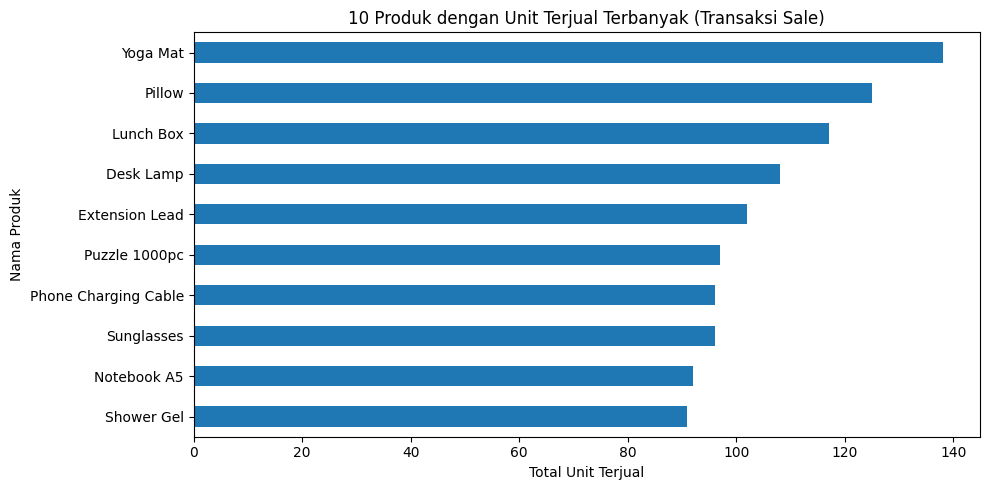

In [16]:
# 10 barang dengan unit terjual terbanyak (sale saja)
sales_data = movement_data[movement_data["movement_type"].eq("sale")].copy()

if not sales_data.empty and "units_out" in sales_data.columns:
    top_selling_products = (
        sales_data.groupby("product_name")["units_out"]
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )
    display(top_selling_products.rename("unit_terjual").to_frame())

    plt.figure(figsize=(10, 5))
    top_selling_products.sort_values().plot(kind="barh")
    plt.title("10 Produk dengan Unit Terjual Terbanyak (Transaksi Sale)")
    plt.xlabel("Total Unit Terjual")
    plt.ylabel("Nama Produk")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ditemukan transaksi dengan movement_type == 'sale'.")

,unit_diterima
product_name,
Phone Charging Cable,1953.0
Extension Lead,1405.0
Coffee Grinder,1255.0
Yoga Mat,1233.0
LED Bulb Pack,962.0
Bath Towel,790.0
Sunglasses,766.0
Notebook A5,684.0
Umbrella,642.0


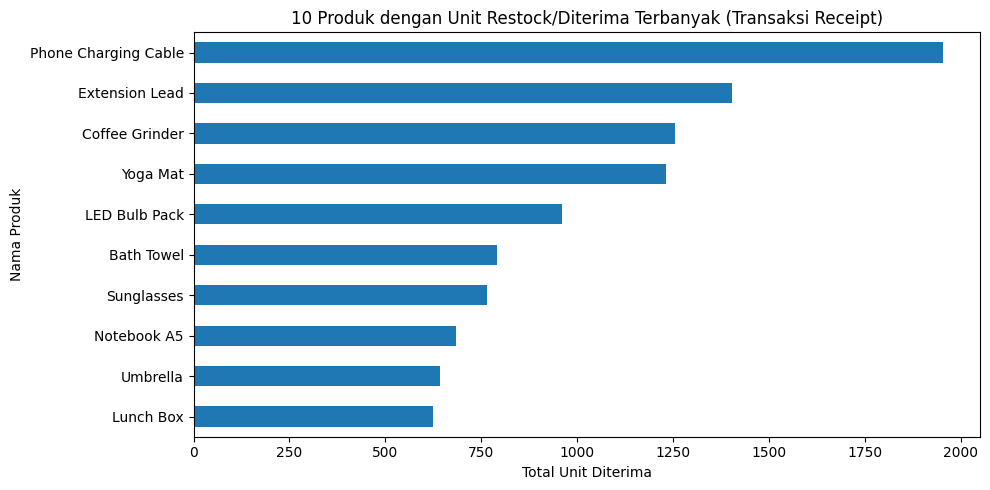

In [17]:
# 10 barang dengan unit diterima/restock terbanyak (receipt saja)
receipt_data = movement_data[movement_data["movement_type"].eq("receipt")].copy()

if not receipt_data.empty and "units_in" in receipt_data.columns:
    top_restocked_products = (
        receipt_data.groupby("product_name")["units_in"]
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )
    display(top_restocked_products.rename("unit_diterima").to_frame())

    plt.figure(figsize=(10, 5))
    top_restocked_products.sort_values().plot(kind="barh")
    plt.title("10 Produk dengan Unit Restock/Diterima Terbanyak (Transaksi Receipt)")
    plt.xlabel("Total Unit Diterima")
    plt.ylabel("Nama Produk")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ditemukan transaksi dengan movement_type == 'receipt'.")

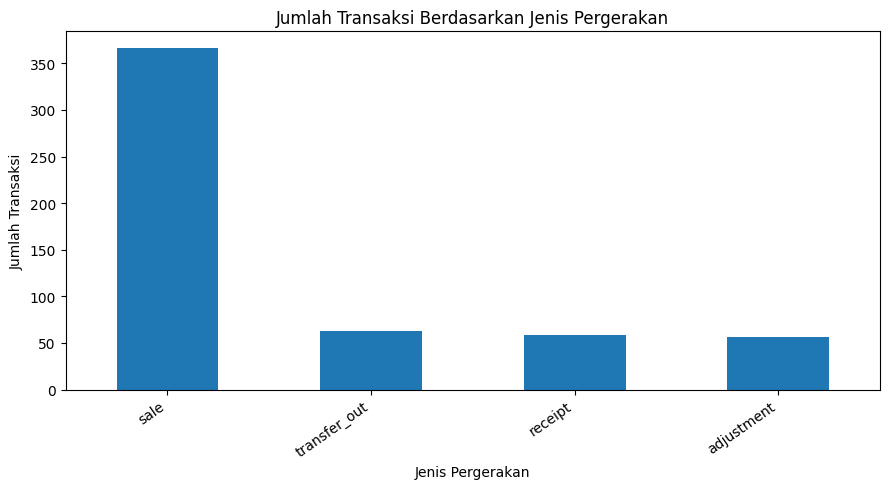

In [18]:
# Visualisasi jumlah transaksi berdasarkan jenis pergerakan
jumlah_per_jenis = movement_data["movement_type"].value_counts()

plt.figure(figsize=(9, 5))
jumlah_per_jenis.plot(kind="bar")
plt.title("Jumlah Transaksi Berdasarkan Jenis Pergerakan")
plt.xlabel("Jenis Pergerakan")
plt.ylabel("Jumlah Transaksi")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 7. Estimasi Stok Akhir dan Early Warning Reorder Point

Pada dataset referensi, estimasi stok dihitung menggunakan rumus:

`current_stock = opening_on_hand + sum(quantity_change)`

Item dengan `current_stock` di bawah atau sama dengan `reorder_point` ditandai sebagai peringatan pengadaan ulang. Ini merupakan simulasi analitis pada dataset referensi, bukan rekomendasi kuantitas pembelian aktual ROKKUS.

In [19]:
total_perubahan = (
    stock_movements.groupby("stock_item_id")["quantity_change"]
    .sum()
    .rename("total_quantity_change")
)

stock_analysis = stock_items.merge(
    total_perubahan,
    left_on="id",
    right_index=True,
    how="left"
)

stock_analysis["total_quantity_change"] = stock_analysis["total_quantity_change"].fillna(0)
stock_analysis["current_stock"] = (
    stock_analysis["opening_on_hand"] + stock_analysis["total_quantity_change"]
)

stock_analysis["reorder_alert"] = np.where(
    stock_analysis["current_stock"] <= stock_analysis["reorder_point"],
    "Perlu evaluasi reorder",
    "Di atas reorder point"
)

display(stock_analysis[
    ["product_name", "opening_on_hand", "total_quantity_change",
     "current_stock", "reorder_point", "reorder_alert"]
].sort_values("current_stock").head(20))

,product_name,opening_on_hand,total_quantity_change,current_stock,reorder_point,reorder_alert
13,Pillow,162,-48,114,188,Perlu evaluasi reorder
73,Desk Lamp,184,-63,121,143,Perlu evaluasi reorder
6,Pillow,160,-24,136,216,Perlu evaluasi reorder
64,Yoga Mat,181,-43,138,193,Perlu evaluasi reorder
76,Kitchen Scale,154,-16,138,84,Di atas reorder point
17,Umbrella,172,-23,149,102,Di atas reorder point
34,Yoga Mat,167,-17,150,213,Perlu evaluasi reorder
42,Kitchen Scale,191,-38,153,215,Perlu evaluasi reorder
47,Sunglasses,185,-25,160,103,Di atas reorder point
5,Hand Cream,213,-42,171,210,Perlu evaluasi reorder


In [20]:
# Daftar item yang berada di bawah atau sama dengan reorder point
items_below_reorder = stock_analysis[
    stock_analysis["current_stock"] <= stock_analysis["reorder_point"]
].copy()

print("Jumlah item pada/bawah reorder point:", len(items_below_reorder))
display(items_below_reorder[
    ["product_name", "current_stock", "reorder_point", "reorder_alert"]
].sort_values("current_stock"))

Jumlah item pada/bawah reorder point: 7


,product_name,current_stock,reorder_point,reorder_alert
13,Pillow,114,188,Perlu evaluasi reorder
73,Desk Lamp,121,143,Perlu evaluasi reorder
6,Pillow,136,216,Perlu evaluasi reorder
64,Yoga Mat,138,193,Perlu evaluasi reorder
34,Yoga Mat,150,213,Perlu evaluasi reorder
42,Kitchen Scale,153,215,Perlu evaluasi reorder
5,Hand Cream,171,210,Perlu evaluasi reorder


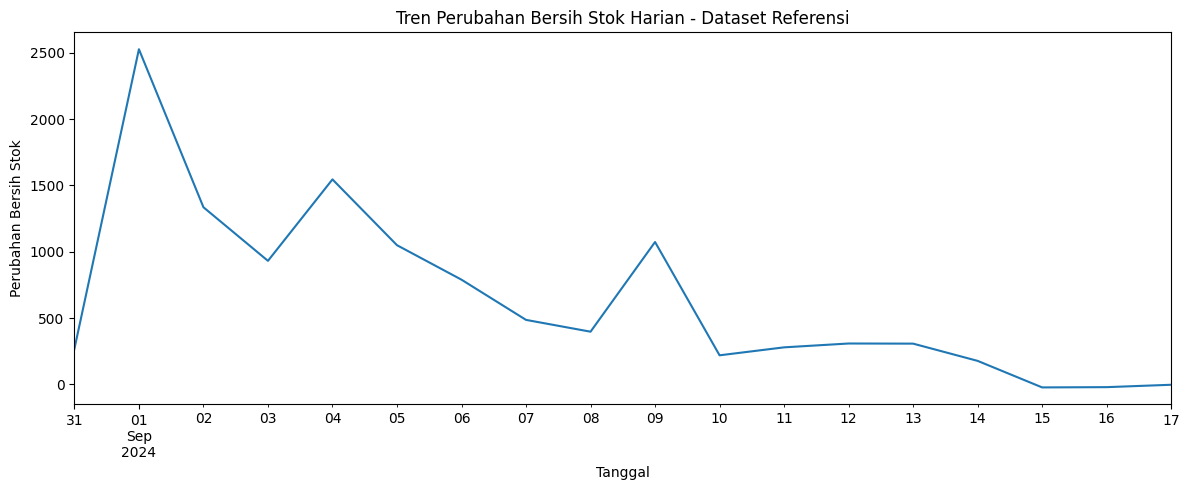

In [21]:
# Tren transaksi harian berdasarkan quantity_change (perubahan bersih, bukan penjualan)
if "moved_at" in stock_movements.columns:
    daily_net_change = (
        stock_movements.dropna(subset=["moved_at"])
        .set_index("moved_at")["quantity_change"]
        .resample("D").sum()
    )
    plt.figure(figsize=(12, 5))
    daily_net_change.plot()
    plt.title("Tren Perubahan Bersih Stok Harian - Dataset Referensi")
    plt.xlabel("Tanggal")
    plt.ylabel("Perubahan Bersih Stok")
    plt.tight_layout()
    plt.show()

## 8. Menjelaskan Pemetaan Konsep ke Konteks ROKKUS

Dataset referensi menggunakan contoh barang umum/non-kuliner. Karena itu, nama barang dan angka dari dataset tersebut tidak dipetakan satu per satu menjadi bahan ROKKUS.

Pemetaan yang dapat dilakukan pada tingkat **konsep data**:
- `reorder_point` → konsep batas minimum stok bahan baku atau produk jadi.
- `lead_time_days` → konsep lama waktu tunggu pemasok. Nilainya perlu dikumpulkan dari pemasok ROKKUS.
- `movement_type` → konsep jenis aktivitas stok masuk dan keluar. Kategori transaksi pada aplikasi ROKKUS harus mengikuti proses bisnis yang disepakati.
- `counted_at` dan `moved_at` → konsep pencatatan waktu stok dan waktu transaksi.

Contoh bahan yang relevan dengan konteks ROKKUS berdasarkan informasi proyek antara lain roti kukus hijau siap pakai, berbagai selai, telur, sosis, smoked beef, mayones, dan keju. **Notebook ini tidak mengasumsikan nilai masa simpan, lead time, atau reorder point aktual untuk bahan-bahan tersebut.**

## 9. Memuat Dataset Simulasi ROKKUS

Unggah dua file final berikut ke Google Colab jika belum tersedia:
- `dataset_bahan_baku_final.csv`
- `dataset_produk_jadi_final.csv`

Notebook akan mencari file di beberapa lokasi umum. Jika belum ditemukan, jalankan cell unggah file.

In [22]:
# Cari file di lokasi kerja Colab dan struktur folder proyek
candidate_roots = [
    Path("/content/data/data-science/data/processed"),
    Path("/content/data/processed"),
    Path("/content"),
    Path("data/data-science/data/processed"),
    Path(".")
]

def cari_file(nama_file):
    for root in candidate_roots:
        kandidat = root / nama_file
        if kandidat.exists():
            return kandidat
    return None

path_bahan = cari_file("dataset_bahan_baku_final.csv")
path_produk = cari_file("dataset_produk_jadi_final.csv")

print("Path bahan baku:", path_bahan)
print("Path produk jadi:", path_produk)

Path bahan baku: None
Path produk jadi: None


In [24]:
# Jika salah satu file belum ditemukan, unggah kedua CSV melalui dialog Colab
if path_bahan is None or path_produk is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        print("File yang diunggah:", list(uploaded.keys()))
    except Exception:
        print("Unggah file CSV secara manual ke folder kerja notebook, lalu jalankan ulang cell ini.")

path_bahan = cari_file("dataset_bahan_baku_final.csv")
path_produk = cari_file("dataset_produk_jadi_final.csv")

if path_bahan is None or path_produk is None:
    raise FileNotFoundError(
        "Kedua file final belum ditemukan. Pastikan dataset_bahan_baku_final.csv "
        "dan dataset_produk_jadi_final.csv sudah diunggah."
    )

df_bahan = pd.read_csv(path_bahan)
df_produk = pd.read_csv(path_produk)

print("Dataset bahan baku:", df_bahan.shape)
print("Dataset produk jadi:", df_produk.shape)
display(df_bahan.head())
display(df_produk.head())

Saving dataset_bahan_baku_final.csv to dataset_bahan_baku_final.csv
Saving dataset_produk_jadi_final.csv to dataset_produk_jadi_final.csv
File yang diunggah: ['dataset_bahan_baku_final.csv', 'dataset_produk_jadi_final.csv']
Dataset bahan baku: (18, 13)
Dataset produk jadi: (29, 11)


,material_id,material_name,category,unit,stok_awal,total_masuk,total_keluar,stok_akhir,min_stock,stock_status,periode_mulai,periode_selesai,data_basis
0,BB001,Roti Kukus Hijau (Polos),Base produk supplier,pcs,151,752,751,152,76,Aman,2026-09-01,2026-09-30,Dataset sintetis; stok masuk dan stok awal merupakan asumsi; stok keluar dihitung dari transaksi...
1,BB002,Selai Lotus Biscoff,Isian manis,gram,156,780,780,156,157,Menipis,2026-09-01,2026-09-30,Dataset sintetis; stok masuk dan stok awal merupakan asumsi; stok keluar dihitung dari transaksi...
2,BB003,Selai Coklat / Coklat Crunchy,Isian manis,gram,364,1820,1820,364,182,Aman,2026-09-01,2026-09-30,Dataset sintetis; stok masuk dan stok awal merupakan asumsi; stok keluar dihitung dari transaksi...
3,BB004,Selai Nutella,Isian manis,gram,336,1680,1680,336,168,Aman,2026-09-01,2026-09-30,Dataset sintetis; stok masuk dan stok awal merupakan asumsi; stok keluar dihitung dari transaksi...
4,BB005,Coklat Silverqueen,Isian manis,gram,148,740,740,148,74,Aman,2026-09-01,2026-09-30,Dataset sintetis; stok masuk dan stok awal merupakan asumsi; stok keluar dihitung dari transaksi...


,product_id,product_name,category,price,tanggal_stok,stok_awal,total_masuk,total_keluar,stok_akhir,min_stock,stock_status
0,PR001,Lotus Biscoff,Roti Manis,18000,2026-09-01,16,35,39,12,4,Aman
1,PR002,Coklat Keju,Roti Manis,14000,2026-09-01,29,47,28,48,3,Aman
2,PR003,Coklat Kacang,Roti Manis,15000,2026-09-01,24,23,33,14,4,Aman
3,PR004,Nutella Keju,Roti Manis,18000,2026-09-01,20,17,37,0,4,Habis
4,PR005,Silverqueen Keju,Roti Manis,21000,2026-09-01,17,22,21,18,3,Aman


## 10. Pemeriksaan Struktur dan Kualitas Dataset Simulasi ROKKUS

### Validasi Nama Kolom Dataset Final

Sebelum EDA dan pengujian, notebook memastikan seluruh kolom yang dibutuhkan tersedia. Jika ada nama kolom yang berbeda, proses dihentikan dengan pesan yang menunjukkan kolom yang perlu diperbaiki.

In [25]:
# Validasi kolom yang digunakan oleh visualisasi dan pengujian
required_bahan = {
    "stock_status", "stok_akhir", "min_stock", "material_name", "category",
    "stok_awal", "total_masuk", "total_keluar"
}
required_produk = {
    "stock_status", "stok_akhir", "min_stock", "product_name", "category",
    "stok_awal", "total_masuk", "total_keluar"
}

missing_bahan = sorted(required_bahan - set(df_bahan.columns))
missing_produk = sorted(required_produk - set(df_produk.columns))

print("Kolom dataset bahan baku:", df_bahan.columns.tolist())
print("Kolom dataset produk jadi:", df_produk.columns.tolist())

if missing_bahan or missing_produk:
    pesan = []
    if missing_bahan:
        pesan.append(f"Kolom yang belum ada pada dataset bahan baku: {missing_bahan}")
    if missing_produk:
        pesan.append(f"Kolom yang belum ada pada dataset produk jadi: {missing_produk}")
    raise ValueError("\n".join(pesan))

print("Validasi skema berhasil: seluruh kolom yang dibutuhkan tersedia.")


Kolom dataset bahan baku: ['material_id', 'material_name', 'category', 'unit', 'stok_awal', 'total_masuk', 'total_keluar', 'stok_akhir', 'min_stock', 'stock_status', 'periode_mulai', 'periode_selesai', 'data_basis']
Kolom dataset produk jadi: ['product_id', 'product_name', 'category', 'price', 'tanggal_stok', 'stok_awal', 'total_masuk', 'total_keluar', 'stok_akhir', 'min_stock', 'stock_status']
Validasi skema berhasil: seluruh kolom yang dibutuhkan tersedia.


In [26]:
for nama, df in [("Bahan Baku", df_bahan), ("Produk Jadi", df_produk)]:
    print(f"\n===== {nama.upper()} =====")
    print("Ukuran:", df.shape)
    print("Kolom:", df.columns.tolist())
    print("\nTipe data:")
    display(df.dtypes.to_frame("dtype"))
    print("\nMissing values:")
    display(df.isna().sum().to_frame("jumlah_missing"))
    print("Duplikat baris:", df.duplicated().sum())


===== BAHAN BAKU =====
Ukuran: (18, 13)
Kolom: ['material_id', 'material_name', 'category', 'unit', 'stok_awal', 'total_masuk', 'total_keluar', 'stok_akhir', 'min_stock', 'stock_status', 'periode_mulai', 'periode_selesai', 'data_basis']

Tipe data:


,dtype
material_id,object
material_name,object
category,object
unit,object
stok_awal,int64
total_masuk,int64
total_keluar,int64
stok_akhir,int64
min_stock,int64
stock_status,object



Missing values:


,jumlah_missing
material_id,0
material_name,0
category,0
unit,0
stok_awal,0
total_masuk,0
total_keluar,0
stok_akhir,0
min_stock,0
stock_status,0


Duplikat baris: 0

===== PRODUK JADI =====
Ukuran: (29, 11)
Kolom: ['product_id', 'product_name', 'category', 'price', 'tanggal_stok', 'stok_awal', 'total_masuk', 'total_keluar', 'stok_akhir', 'min_stock', 'stock_status']

Tipe data:


,dtype
product_id,object
product_name,object
category,object
price,int64
tanggal_stok,object
stok_awal,int64
total_masuk,int64
total_keluar,int64
stok_akhir,int64
min_stock,int64



Missing values:


,jumlah_missing
product_id,0
product_name,0
category,0
price,0
tanggal_stok,0
stok_awal,0
total_masuk,0
total_keluar,0
stok_akhir,0
min_stock,0


Duplikat baris: 0


## 11. EDA dan Visualisasi Dataset Simulasi ROKKUS

Visualisasi berikut menggunakan kolom dari dataset final. Grafik disimpan ke folder `outputs` agar dapat dimasukkan ke repositori proyek.

In [27]:
# Tentukan folder output yang konsisten untuk Google Colab atau lokal
OUTPUTS = Path("/content/data/data-science/outputs")
if not Path("/content").exists():
    OUTPUTS = Path("outputs")
OUTPUTS.mkdir(parents=True, exist_ok=True)

print("Folder output:", OUTPUTS.resolve())

Folder output: /content/data/data-science/outputs


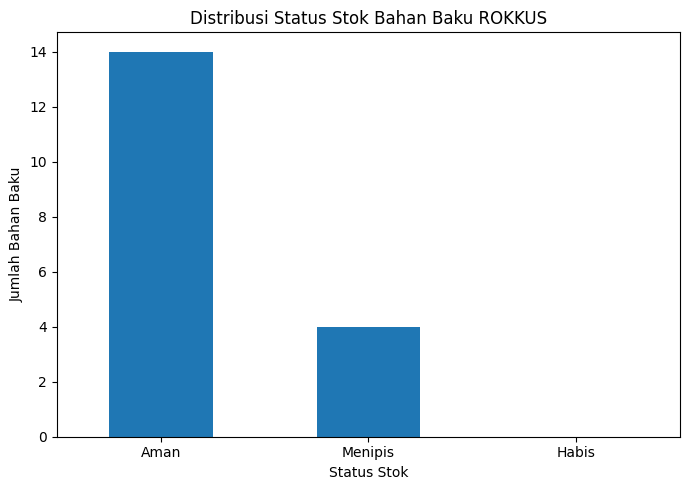

,jumlah
stock_status,
Aman,14
Menipis,4
Habis,0


In [28]:
# 1. Distribusi status stok bahan baku
if {"stock_status"}.issubset(df_bahan.columns):
    status_bahan = df_bahan["stock_status"].value_counts().reindex(
        ["Aman", "Menipis", "Habis"], fill_value=0
    )
    plt.figure(figsize=(7, 5))
    status_bahan.plot(kind="bar")
    plt.title("Distribusi Status Stok Bahan Baku ROKKUS")
    plt.xlabel("Status Stok")
    plt.ylabel("Jumlah Bahan Baku")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(OUTPUTS / "eda_status_bahan_baku.png", dpi=300, bbox_inches="tight")
    plt.show()
    display(status_bahan.to_frame("jumlah"))

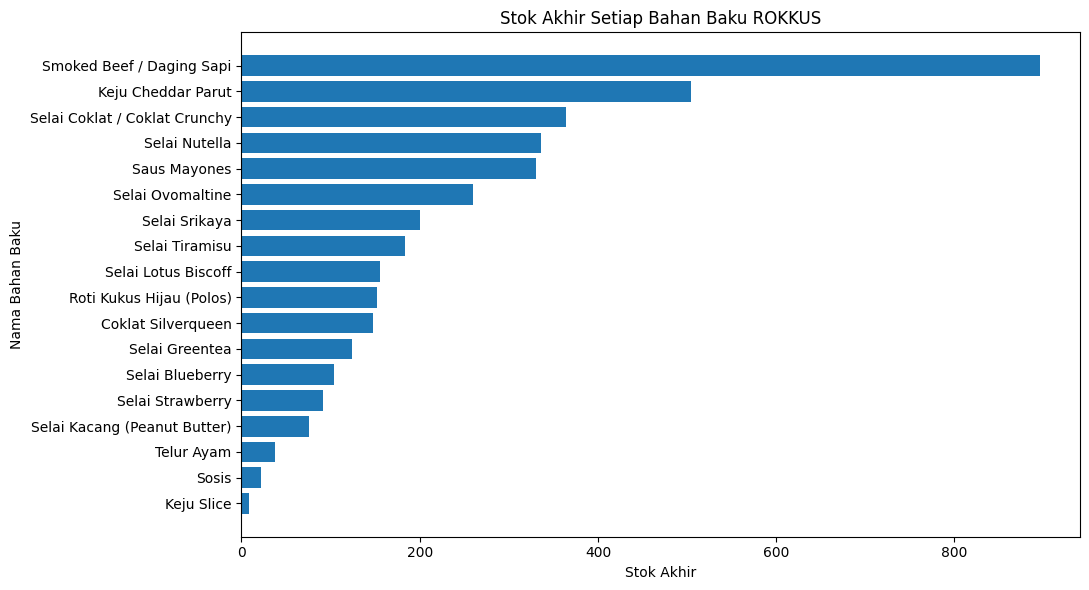

In [29]:
# 2. Stok akhir setiap bahan baku
if {"material_name", "stok_akhir"}.issubset(df_bahan.columns):
    data_plot = df_bahan.sort_values("stok_akhir", ascending=True)
    plt.figure(figsize=(11, 6))
    plt.barh(data_plot["material_name"], data_plot["stok_akhir"])
    plt.title("Stok Akhir Setiap Bahan Baku ROKKUS")
    plt.xlabel("Stok Akhir")
    plt.ylabel("Nama Bahan Baku")
    plt.tight_layout()
    plt.savefig(OUTPUTS / "eda_stok_akhir_bahan_baku.png", dpi=300, bbox_inches="tight")
    plt.show()

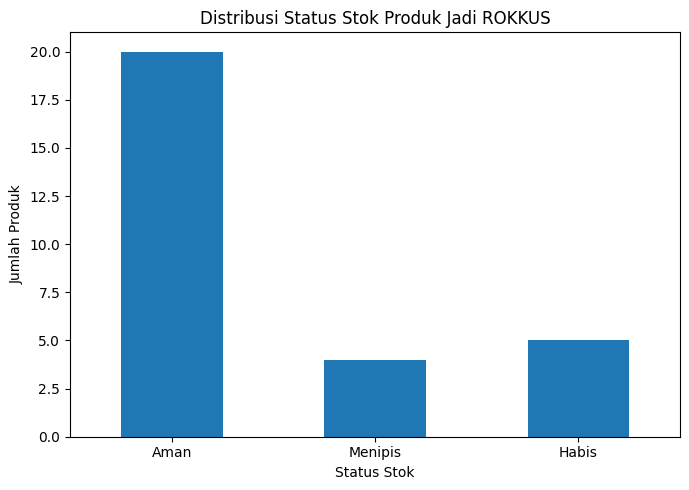

,jumlah
stock_status,
Aman,20
Menipis,4
Habis,5


In [30]:
# 3. Distribusi status stok produk jadi
if "stock_status" in df_produk.columns:
    status_produk = df_produk["stock_status"].value_counts().reindex(
        ["Aman", "Menipis", "Habis"], fill_value=0
    )
    plt.figure(figsize=(7, 5))
    status_produk.plot(kind="bar")
    plt.title("Distribusi Status Stok Produk Jadi ROKKUS")
    plt.xlabel("Status Stok")
    plt.ylabel("Jumlah Produk")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(OUTPUTS / "eda_status_produk_jadi.png", dpi=300, bbox_inches="tight")
    plt.show()
    display(status_produk.to_frame("jumlah"))

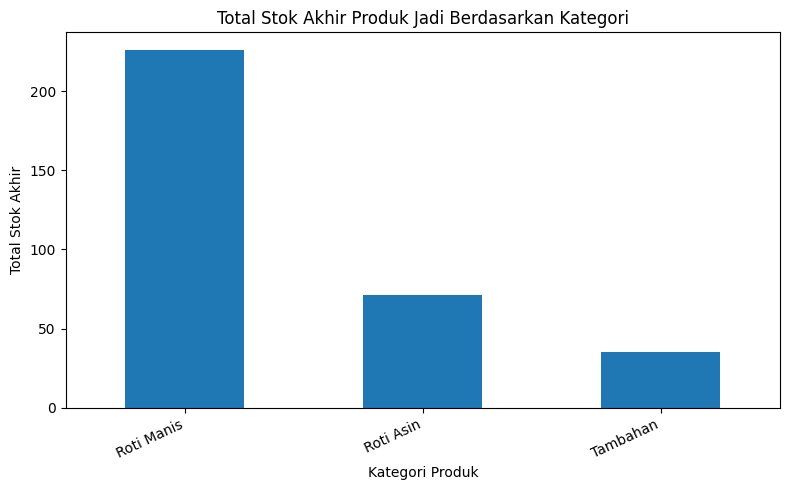

,total_stok_akhir
category,
Roti Manis,226
Roti Asin,71
Tambahan,35


In [31]:
# 4. Total stok akhir produk berdasarkan kategori
if {"category", "stok_akhir"}.issubset(df_produk.columns):
    stok_kategori = df_produk.groupby("category")["stok_akhir"].sum().sort_values(ascending=False)
    plt.figure(figsize=(8, 5))
    stok_kategori.plot(kind="bar")
    plt.title("Total Stok Akhir Produk Jadi Berdasarkan Kategori")
    plt.xlabel("Kategori Produk")
    plt.ylabel("Total Stok Akhir")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUTS / "eda_stok_produk_per_kategori.png", dpi=300, bbox_inches="tight")
    plt.show()
    display(stok_kategori.to_frame("total_stok_akhir"))

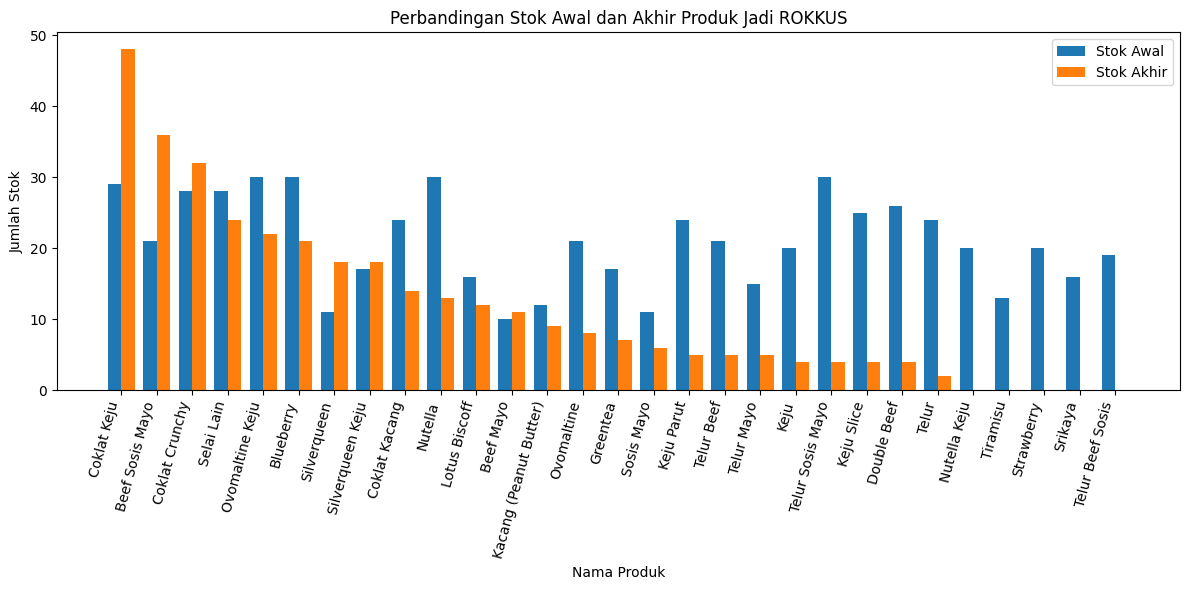

Jumlah grafik EDA ROKKUS: 5


In [32]:
# 5. Perbandingan stok awal dan stok akhir produk jadi
if {"product_name", "stok_awal", "stok_akhir"}.issubset(df_produk.columns):
    plot_produk = df_produk.sort_values("stok_akhir", ascending=False)
    x = np.arange(len(plot_produk))
    width = 0.38
    plt.figure(figsize=(12, 6))
    plt.bar(x - width/2, plot_produk["stok_awal"], width, label="Stok Awal")
    plt.bar(x + width/2, plot_produk["stok_akhir"], width, label="Stok Akhir")
    plt.title("Perbandingan Stok Awal dan Akhir Produk Jadi ROKKUS")
    plt.xlabel("Nama Produk")
    plt.ylabel("Jumlah Stok")
    plt.xticks(x, plot_produk["product_name"], rotation=75, ha="right")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUTS / "eda_perbandingan_stok_produk.png", dpi=300, bbox_inches="tight")
    plt.show()

print("Jumlah grafik EDA ROKKUS:", len(list(OUTPUTS.glob("eda_*.png"))))

## 12. Pengujian Fungsional Dataset Final ROKKUS

Pengujian ini memeriksa:
- Dataset tidak kosong.
- Kolom stok dan status penting tidak memiliki nilai kosong.
- Stok akhir tidak negatif.
- Status sesuai dengan aturan klasifikasi: `Habis` jika stok akhir ≤ 0, `Menipis` jika stok akhir ≤ minimum stock, dan `Aman` jika di atas minimum stock.
- Rumus stok akhir sesuai jika kolom yang diperlukan tersedia: `stok_awal + total_masuk - total_keluar = stok_akhir`.

Pengujian rumus akan dilewati secara eksplisit jika kolom pendukung tidak tersedia; hal tersebut bukan dinyatakan sebagai PASS.

In [33]:
hasil_pengujian = []

def catat_uji(nama_dataset, nama_uji, kondisi):
    hasil_pengujian.append({
        "Dataset": nama_dataset,
        "Pengujian": nama_uji,
        "Hasil": "PASS" if bool(kondisi) else "FAIL"
    })

def uji_dataset_stok(nama, df):
    kolom_wajib = ["stok_akhir", "min_stock", "stock_status"]
    missing_kolom = [kolom for kolom in kolom_wajib if kolom not in df.columns]

    catat_uji(nama, "Dataset tidak kosong", len(df) > 0)
    catat_uji(nama, "Kolom stok/status tersedia", len(missing_kolom) == 0)

    if missing_kolom:
        print(f"{nama}: pengujian berikutnya dilewati; kolom tidak tersedia: {missing_kolom}")
        return

    catat_uji(
        nama, "Tidak ada nilai kosong pada stok dan status",
        df[kolom_wajib].notna().all().all()
    )
    catat_uji(nama, "Stok akhir tidak negatif", (df["stok_akhir"] >= 0).all())

    status_valid = np.select(
        [df["stok_akhir"] <= 0, df["stok_akhir"] <= df["min_stock"]],
        ["Habis", "Menipis"],
        default="Aman"
    )
    catat_uji(
        nama, "Kesesuaian status stok",
        (df["stock_status"].astype(str).to_numpy() == status_valid).all()
    )

    kolom_rumus = ["stok_awal", "total_masuk", "total_keluar", "stok_akhir"]
    if all(k in df.columns for k in kolom_rumus):
        stok_hitung = df["stok_awal"] + df["total_masuk"] - df["total_keluar"]
        catat_uji(nama, "Rumus stok akhir", np.isclose(stok_hitung, df["stok_akhir"]).all())
    else:
        print(f"{nama}: rumus stok akhir tidak diuji karena kolom {kolom_rumus} tidak lengkap.")

uji_dataset_stok("Bahan Baku", df_bahan)
uji_dataset_stok("Produk Jadi", df_produk)

df_hasil_uji = pd.DataFrame(hasil_pengujian)
display(df_hasil_uji)

print("Total pengujian:", len(df_hasil_uji))
print("PASS:", (df_hasil_uji["Hasil"] == "PASS").sum())
print("FAIL:", (df_hasil_uji["Hasil"] == "FAIL").sum())

df_hasil_uji.to_csv(OUTPUTS / "hasil_pengujian_dataset_final.csv", index=False)
print("Hasil pengujian disimpan ke:", OUTPUTS / "hasil_pengujian_dataset_final.csv")

,Dataset,Pengujian,Hasil
0,Bahan Baku,Dataset tidak kosong,PASS
1,Bahan Baku,Kolom stok/status tersedia,PASS
2,Bahan Baku,Tidak ada nilai kosong pada stok dan status,PASS
3,Bahan Baku,Stok akhir tidak negatif,PASS
4,Bahan Baku,Kesesuaian status stok,PASS
5,Bahan Baku,Rumus stok akhir,PASS
6,Produk Jadi,Dataset tidak kosong,PASS
7,Produk Jadi,Kolom stok/status tersedia,PASS
8,Produk Jadi,Tidak ada nilai kosong pada stok dan status,PASS
9,Produk Jadi,Stok akhir tidak negatif,PASS


Total pengujian: 12
PASS: 12
FAIL: 0
Hasil pengujian disimpan ke: /content/data/data-science/outputs/hasil_pengujian_dataset_final.csv


## 13. Ringkasan Temuan dan Kesimpulan

Setelah seluruh cell dijalankan, cell ringkasan otomatis di bawah akan menyusun angka aktual berdasarkan dataset yang sedang digunakan. Gunakan hasil tersebut sebagai dasar kesimpulan laporan; jangan menyalin angka dari eksekusi sebelumnya.

Ringkasan mencakup kualitas dataset referensi, jumlah unit terjual dan diterima, item pada/bawah reorder point, distribusi status stok bahan baku dan produk jadi, serta hasil pengujian PASS/FAIL.

### Implikasi untuk pengembangan aplikasi

Aplikasi dapat menyediakan pemantauan stok saat ini, histori barang masuk/keluar, dan peringatan ketika stok mencapai batas minimum. Nilai minimum stock, waktu tunggu pemasok, satuan bahan, serta informasi masa simpan perlu dikonfirmasi kepada UMKM sebelum digunakan sebagai dasar keputusan operasional. Dataset publik hanya digunakan sebagai referensi metode, sedangkan dataset ROKKUS pada notebook ini merupakan simulasi.

In [34]:
# Ringkasan temuan otomatis berdasarkan data yang sedang dianalisis
from IPython.display import Markdown, display

def ringkas_status(df, nama_kolom="stock_status"):
    if nama_kolom not in df.columns:
        return "Kolom status tidak tersedia."
    counts = df[nama_kolom].value_counts()
    return ", ".join(f"{status}: {int(jumlah)}" for status, jumlah in counts.items()) or "Tidak ada data"

jumlah_sale = int(sales_data["units_out"].sum()) if "units_out" in sales_data.columns and not sales_data.empty else 0
jumlah_receipt = int(receipt_data["units_in"].sum()) if "units_in" in receipt_data.columns and not receipt_data.empty else 0
jumlah_reorder = int(len(items_below_reorder)) if "items_below_reorder" in globals() else 0
pass_count = int((df_hasil_uji["Hasil"] == "PASS").sum()) if "df_hasil_uji" in globals() and "Hasil" in df_hasil_uji.columns else 0
fail_count = int((df_hasil_uji["Hasil"] == "FAIL").sum()) if "df_hasil_uji" in globals() and "Hasil" in df_hasil_uji.columns else 0

# Tabel ringkasan juga ditampilkan agar angka mudah diperiksa.
ringkasan_aktual = pd.DataFrame({
    "Indikator": [
        "Jumlah baris stock_items referensi",
        "Jumlah baris stock_movements referensi",
        "Total unit terjual (sale / units_out)",
        "Total unit diterima (receipt / units_in)",
        "Item referensi pada/bawah reorder point",
        "Jumlah bahan baku ROKKUS",
        "Jumlah produk jadi ROKKUS",
        "Pengujian PASS",
        "Pengujian FAIL"
    ],
    "Nilai aktual": [
        len(stock_items), len(stock_movements), jumlah_sale, jumlah_receipt, jumlah_reorder,
        len(df_bahan), len(df_produk), pass_count, fail_count
    ]
})
display(ringkasan_aktual)

kesimpulan_otomatis = f"""
### Ringkasan hasil eksekusi aktual

- Dataset referensi terdiri dari **{len(stock_items)} item inventaris** dan **{len(stock_movements)} catatan pergerakan stok**.
- Transaksi `sale` mencatat **{jumlah_sale} unit keluar**, sedangkan transaksi `receipt` mencatat **{jumlah_receipt} unit masuk**. Kedua angka dihitung terpisah agar perubahan bersih stok tidak disalahartikan sebagai penjualan.
- Terdapat **{jumlah_reorder} item referensi** dengan estimasi stok akhir pada atau di bawah reorder point.
- Dataset simulasi ROKKUS memuat **{len(df_bahan)} bahan baku** (status: {ringkas_status(df_bahan)}) dan **{len(df_produk)} produk jadi** (status: {ringkas_status(df_produk)}).
- Pengujian fungsional menghasilkan **{pass_count} PASS** dan **{fail_count} FAIL** dari **{len(df_hasil_uji)} pengujian**.

**Batasan:** dataset publik bukan data operasional ROKKUS. Dataset ROKKUS yang dianalisis merupakan simulasi; nilai minimum stock dan asumsi stok perlu divalidasi oleh UMKM. Informasi masa simpan dan lead time pemasok belum dapat disimpulkan jika belum tersedia datanya.

**Implikasi:** aplikasi dapat dikembangkan untuk memantau stok, mencatat transaksi masuk/keluar, dan memberikan peringatan ketika stok mendekati atau mencapai batas minimum.
"""
display(Markdown(kesimpulan_otomatis))


,Indikator,Nilai aktual
0,Jumlah baris stock_items referensi,80
1,Jumlah baris stock_movements referensi,543
2,Total unit terjual (sale / units_out),1775
3,Total unit diterima (receipt / units_in),14015
4,Item referensi pada/bawah reorder point,7
5,Jumlah bahan baku ROKKUS,18
6,Jumlah produk jadi ROKKUS,29
7,Pengujian PASS,12
8,Pengujian FAIL,0



### Ringkasan hasil eksekusi aktual

- Dataset referensi terdiri dari **80 item inventaris** dan **543 catatan pergerakan stok**.
- Transaksi `sale` mencatat **1775 unit keluar**, sedangkan transaksi `receipt` mencatat **14015 unit masuk**. Kedua angka dihitung terpisah agar perubahan bersih stok tidak disalahartikan sebagai penjualan.
- Terdapat **7 item referensi** dengan estimasi stok akhir pada atau di bawah reorder point.
- Dataset simulasi ROKKUS memuat **18 bahan baku** (status: Aman: 14, Menipis: 4) dan **29 produk jadi** (status: Aman: 20, Habis: 5, Menipis: 4).
- Pengujian fungsional menghasilkan **12 PASS** dan **0 FAIL** dari **12 pengujian**.

**Batasan:** dataset publik bukan data operasional ROKKUS. Dataset ROKKUS yang dianalisis merupakan simulasi; nilai minimum stock dan asumsi stok perlu divalidasi oleh UMKM. Informasi masa simpan dan lead time pemasok belum dapat disimpulkan jika belum tersedia datanya.

**Implikasi:** aplikasi dapat dikembangkan untuk memantau stok, mencatat transaksi masuk/keluar, dan memberikan peringatan ketika stok mendekati atau mencapai batas minimum.


## 14. Ekspor Output

File visualisasi dan hasil pengujian tersimpan di folder `outputs`. Jalankan cell berikut untuk mengemas seluruh output menjadi ZIP yang dapat diunduh dari Google Colab.

In [35]:
import shutil

zip_path = shutil.make_archive(
    str(OUTPUTS.parent / "hasil_eda_dan_pengujian_rokkus"),
    "zip",
    root_dir=OUTPUTS
)
print("File ZIP berhasil dibuat:", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Di luar Google Colab, file ZIP tersedia pada path di atas.")

File ZIP berhasil dibuat: /content/data/data-science/hasil_eda_dan_pengujian_rokkus.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>